# Pre-Annotation with Grounding DINO + SAM (HuggingFace transformers)

**Runs on Kaggle GPU.** Uses the `transformers` built-in Grounding DINO and SAM —
no external repos needed.

**Setup:** Upload your `cfp_processed` folder as a Kaggle dataset.
Set the dataset path below.

In [4]:
!pip install -q transformers accelerate torch torchvision pillow matplotlib numpy

In [5]:
from pathlib import Path
import numpy as np
from PIL import Image
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import json, time

# ── CONFIG ─────────────────────────────────────────────────────────
# On Kaggle: /kaggle/input/<dataset-name>/cfp_processed
# Locally:   data/cfp_processed
DATA_ROOT = Path("/kaggle/input/datasets/baidarsamir/cfp-test") # ADJUST
OUTPUT_DIR = Path("/kaggle/working/pre_annotation_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

NUM_CLASSES = 10
CLASS_NAMES = {
    0: "background", 1: "building", 2: "window", 3: "sky",
    4: "roof", 5: "door", 6: "tree", 7: "people", 8: "car", 9: "sign",
}
CLASS_COLORS_RGB = {
    0: (0,0,0), 1: (70,70,70), 2: (250,170,30), 3: (70,130,180),
    4: (0,60,100), 5: (153,153,153), 6: (107,142,35), 7: (255,0,0),
    8: (0,0,142), 9: (220,220,0),
}

# Text prompts → class ID mapping for Grounding DINO
# Each prompt is a single noun that Grounding DINO can detect.
PROMPT_TO_CLASS = {
    "building": 1,
    "window": 2,
    "sky": 3,
    "roof": 4,
    "door": 5,
    "tree": 6,
    "person": 7,  # "person" works better than "people" for detection
    "car": 8,
    "sign": 9,
}

# Priority order: later entries overwrite earlier ones in overlapping regions
# (mirrors RTFP's overlap_order logic: small/foreground objects on top)
PAINT_ORDER = ["sky", "building", "roof", "door", "window", "tree", "person", "car", "sign"]

Device: cuda


In [6]:
print(len(list((DATA_ROOT / "test" / "images").glob("*.png"))),
      len(list((DATA_ROOT / "test" / "masks").glob("*.png"))))

61 61


## Load Models

In [7]:
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
from transformers import SamModel, SamProcessor

# ── Grounding DINO ──
gdino_id = "IDEA-Research/grounding-dino-base"
gdino_proc = AutoProcessor.from_pretrained(gdino_id)
gdino_model = AutoModelForZeroShotObjectDetection.from_pretrained(gdino_id).to(DEVICE)
gdino_model.eval()
print("Grounding DINO loaded")

# ── SAM ──
sam_id = "facebook/sam-vit-base"
sam_proc = SamProcessor.from_pretrained(sam_id)
sam_model = SamModel.from_pretrained(sam_id).to(DEVICE)
sam_model.eval()
print("SAM loaded")

preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.74k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (6 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

SAM loaded


## Core Functions

In [10]:
def detect_objects(image: Image.Image, text_prompt: str, box_threshold: float = 0.25):
    inputs = gdino_proc(images=image, text=text_prompt + ".", return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        outputs = gdino_model(**inputs)

    results = gdino_proc.post_process_grounded_object_detection(
        outputs,
        inputs["input_ids"],
        threshold=box_threshold,
        text_threshold=box_threshold,
        target_sizes=[image.size[::-1]],
    )[0]

    boxes = results["boxes"].cpu().numpy()
    scores = results["scores"].cpu().numpy()
    return boxes, scores

def segment_boxes(image: Image.Image, boxes: np.ndarray):
    """
    Run SAM with box prompts. Returns binary masks (N, H, W).
    """
    if len(boxes) == 0:
        return np.zeros((0, *image.size[::-1]), dtype=bool)

    # SAM expects boxes as [[x1, y1, x2, y2]] per image
    input_boxes = [boxes.tolist()]  # batch of 1 image
    inputs = sam_proc(image, input_boxes=input_boxes, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        outputs = sam_model(**inputs)

    masks = sam_proc.image_processor.post_process_masks(
        outputs.pred_masks.cpu(),
        inputs["original_sizes"].cpu(),
        inputs["reshaped_input_sizes"].cpu(),
    )[0]  # (N, 3, H, W) — 3 quality levels per mask

    # Take the highest-quality mask (index 2) for each box
    masks = masks[:, 2, :, :].numpy() > 0  # (N, H, W) bool
    return masks


def pre_annotate_image(image: Image.Image):
    """
    Run full pre-annotation pipeline on one image.
    Returns semantic mask (H, W) with class IDs 0-9.
    """
    h, w = image.size[1], image.size[0]
    semantic_mask = np.zeros((h, w), dtype=np.uint8)  # 0 = background
    detection_counts = {}

    for prompt in PAINT_ORDER:
        class_id = PROMPT_TO_CLASS[prompt]
        boxes, scores = detect_objects(image, prompt)
        detection_counts[prompt] = len(boxes)

        if len(boxes) == 0:
            continue

        masks = segment_boxes(image, boxes)
        # Paint all masks for this class (later classes overwrite)
        for m in masks:
            semantic_mask[m] = class_id

    return semantic_mask, detection_counts

## Run on Test Set

In [11]:
test_images = sorted((DATA_ROOT / "test" / "images").glob("*.png"))
test_masks = sorted((DATA_ROOT / "test" / "masks").glob("*.png"))
print(f"Test images: {len(test_images)}")

results = []  # list of dicts per image
pred_masks_all = {}  # stem → predicted mask

for i, (img_path, gt_path) in enumerate(zip(test_images, test_masks)):
    stem = img_path.stem
    img = Image.open(img_path).convert("RGB")
    gt = np.array(Image.open(gt_path))

    t0 = time.time()
    pred, det_counts = pre_annotate_image(img)
    elapsed = time.time() - t0

    pred_masks_all[stem] = pred
    results.append({
        "stem": stem,
        "time_s": round(elapsed, 2),
        "detection_counts": det_counts,
    })

    # Save predicted mask
    Image.fromarray(pred).save(OUTPUT_DIR / f"{stem}_pred.png")

    if (i + 1) % 5 == 0 or i == 0:
        print(f"  [{i+1}/{len(test_images)}] {stem}: {elapsed:.1f}s, detections={det_counts}")

print(f"\nDone. Mean time per image: {np.mean([r['time_s'] for r in results]):.1f}s")

Test images: 61
  [1/61] 13953539213_bd3a5e2b34_k: 10.3s, detections={'sky': 1, 'building': 2, 'roof': 2, 'door': 5, 'window': 49, 'tree': 3, 'person': 0, 'car': 2, 'sign': 1}
  [5/61] 1650180454307: 10.6s, detections={'sky': 1, 'building': 5, 'roof': 2, 'door': 1, 'window': 24, 'tree': 1, 'person': 2, 'car': 2, 'sign': 3}
  [10/61] 1650180454764: 11.0s, detections={'sky': 1, 'building': 3, 'roof': 3, 'door': 2, 'window': 7, 'tree': 1, 'person': 3, 'car': 2, 'sign': 2}
  [15/61] 2957835532_d675b1634e_k: 11.6s, detections={'sky': 1, 'building': 2, 'roof': 5, 'door': 0, 'window': 81, 'tree': 9, 'person': 4, 'car': 7, 'sign': 0}
  [20/61] IMG_1294: 10.3s, detections={'sky': 2, 'building': 6, 'roof': 2, 'door': 1, 'window': 27, 'tree': 0, 'person': 3, 'car': 1, 'sign': 0}
  [25/61] IMG_1322: 10.9s, detections={'sky': 1, 'building': 9, 'roof': 2, 'door': 4, 'window': 26, 'tree': 3, 'person': 0, 'car': 1, 'sign': 3}
  [30/61] IMG_20220313_113121: 10.8s, detections={'sky': 1, 'building': 7, '

## Evaluate: Per-Class IoU

In [12]:
def compute_iou_per_class(pred, gt, num_classes=10):
    """Returns per-class IoU (NaN if class absent in both pred and gt)."""
    ious = np.full(num_classes, np.nan)
    for c in range(num_classes):
        pred_c = pred == c
        gt_c = gt == c
        intersection = (pred_c & gt_c).sum()
        union = (pred_c | gt_c).sum()
        if union > 0:
            ious[c] = intersection / union
    return ious


# Accumulate per-class IoU across all test images
all_ious = []  # (N_images, 10)
for img_path, gt_path in zip(test_images, test_masks):
    stem = img_path.stem
    pred = pred_masks_all[stem]
    gt = np.array(Image.open(gt_path))
    ious = compute_iou_per_class(pred, gt)
    all_ious.append(ious)

all_ious = np.array(all_ious)  # (N, 10)

# Per-class mean IoU (ignoring NaN = class not present in image)
mean_iou_per_class = np.nanmean(all_ious, axis=0)

print(f"{'Class':<12s}  {'IoU':>6s}")
print("-" * 20)
for c in range(NUM_CLASSES):
    v = mean_iou_per_class[c]
    print(f"{CLASS_NAMES[c]:<12s}  {v*100:5.1f}%" if not np.isnan(v) else f"{CLASS_NAMES[c]:<12s}    N/A")

miou_all = np.nanmean(mean_iou_per_class)
miou_no_bg = np.nanmean(mean_iou_per_class[1:])
print(f"\nmIoU (10 classes): {miou_all*100:.1f}%")
print(f"mIoU (9 classes, no bg): {miou_no_bg*100:.1f}%")

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Class            IoU
--------------------
background     35.2%
building       27.3%
window         44.1%
sky            53.8%
roof            1.6%
door           27.1%
tree           34.2%
people         11.9%
car            39.7%
sign           11.0%

mIoU (10 classes): 28.6%
mIoU (9 classes, no bg): 27.9%


## Detection Counts: Window & Door Analysis

Compare detected window/door counts to ground-truth instance counts
(connected components in GT mask) as a proxy for correction effort.

In [13]:
from scipy import ndimage

def count_instances_gt(mask, class_id):
    """Count connected components of class_id in GT mask."""
    binary = (mask == class_id).astype(np.uint8)
    if binary.sum() == 0:
        return 0
    labelled, n = ndimage.label(binary)
    return n


count_analysis = []
for img_path, gt_path in zip(test_images, test_masks):
    stem = img_path.stem
    gt = np.array(Image.open(gt_path))
    det_counts = next(r["detection_counts"] for r in results if r["stem"] == stem)

    for cls_name, cls_id in [("window", 2), ("door", 5)]:
        gt_count = count_instances_gt(gt, cls_id)
        pred_count = det_counts.get(cls_name, det_counts.get("person", 0)) if cls_name == "people" else det_counts.get(cls_name, 0)
        count_analysis.append({
            "stem": stem,
            "class": cls_name,
            "gt_instances": gt_count,
            "detected_boxes": pred_count,
            "diff": pred_count - gt_count,
        })

# Summary
for cls_name in ["window", "door"]:
    subset = [r for r in count_analysis if r["class"] == cls_name]
    gt_total = sum(r["gt_instances"] for r in subset)
    det_total = sum(r["detected_boxes"] for r in subset)
    diffs = [r["diff"] for r in subset]
    print(f"\n{cls_name.upper()}:")
    print(f"  GT instances total: {gt_total}")
    print(f"  Detected boxes total: {det_total}")
    print(f"  Mean diff (pred-gt): {np.mean(diffs):+.1f} ± {np.std(diffs):.1f}")
    print(f"  Images with under-detection: {sum(1 for d in diffs if d < 0)}")
    print(f"  Images with over-detection:  {sum(1 for d in diffs if d > 0)}")
    print(f"  Images with exact match:     {sum(1 for d in diffs if d == 0)}")


WINDOW:
  GT instances total: 1238
  Detected boxes total: 1930
  Mean diff (pred-gt): +11.3 ± 17.0
  Images with under-detection: 11
  Images with over-detection:  46
  Images with exact match:     4

DOOR:
  GT instances total: 95
  Detected boxes total: 109
  Mean diff (pred-gt): +0.2 ± 1.7
  Images with under-detection: 15
  Images with over-detection:  21
  Images with exact match:     25


## Visualize Overlays (6 samples)

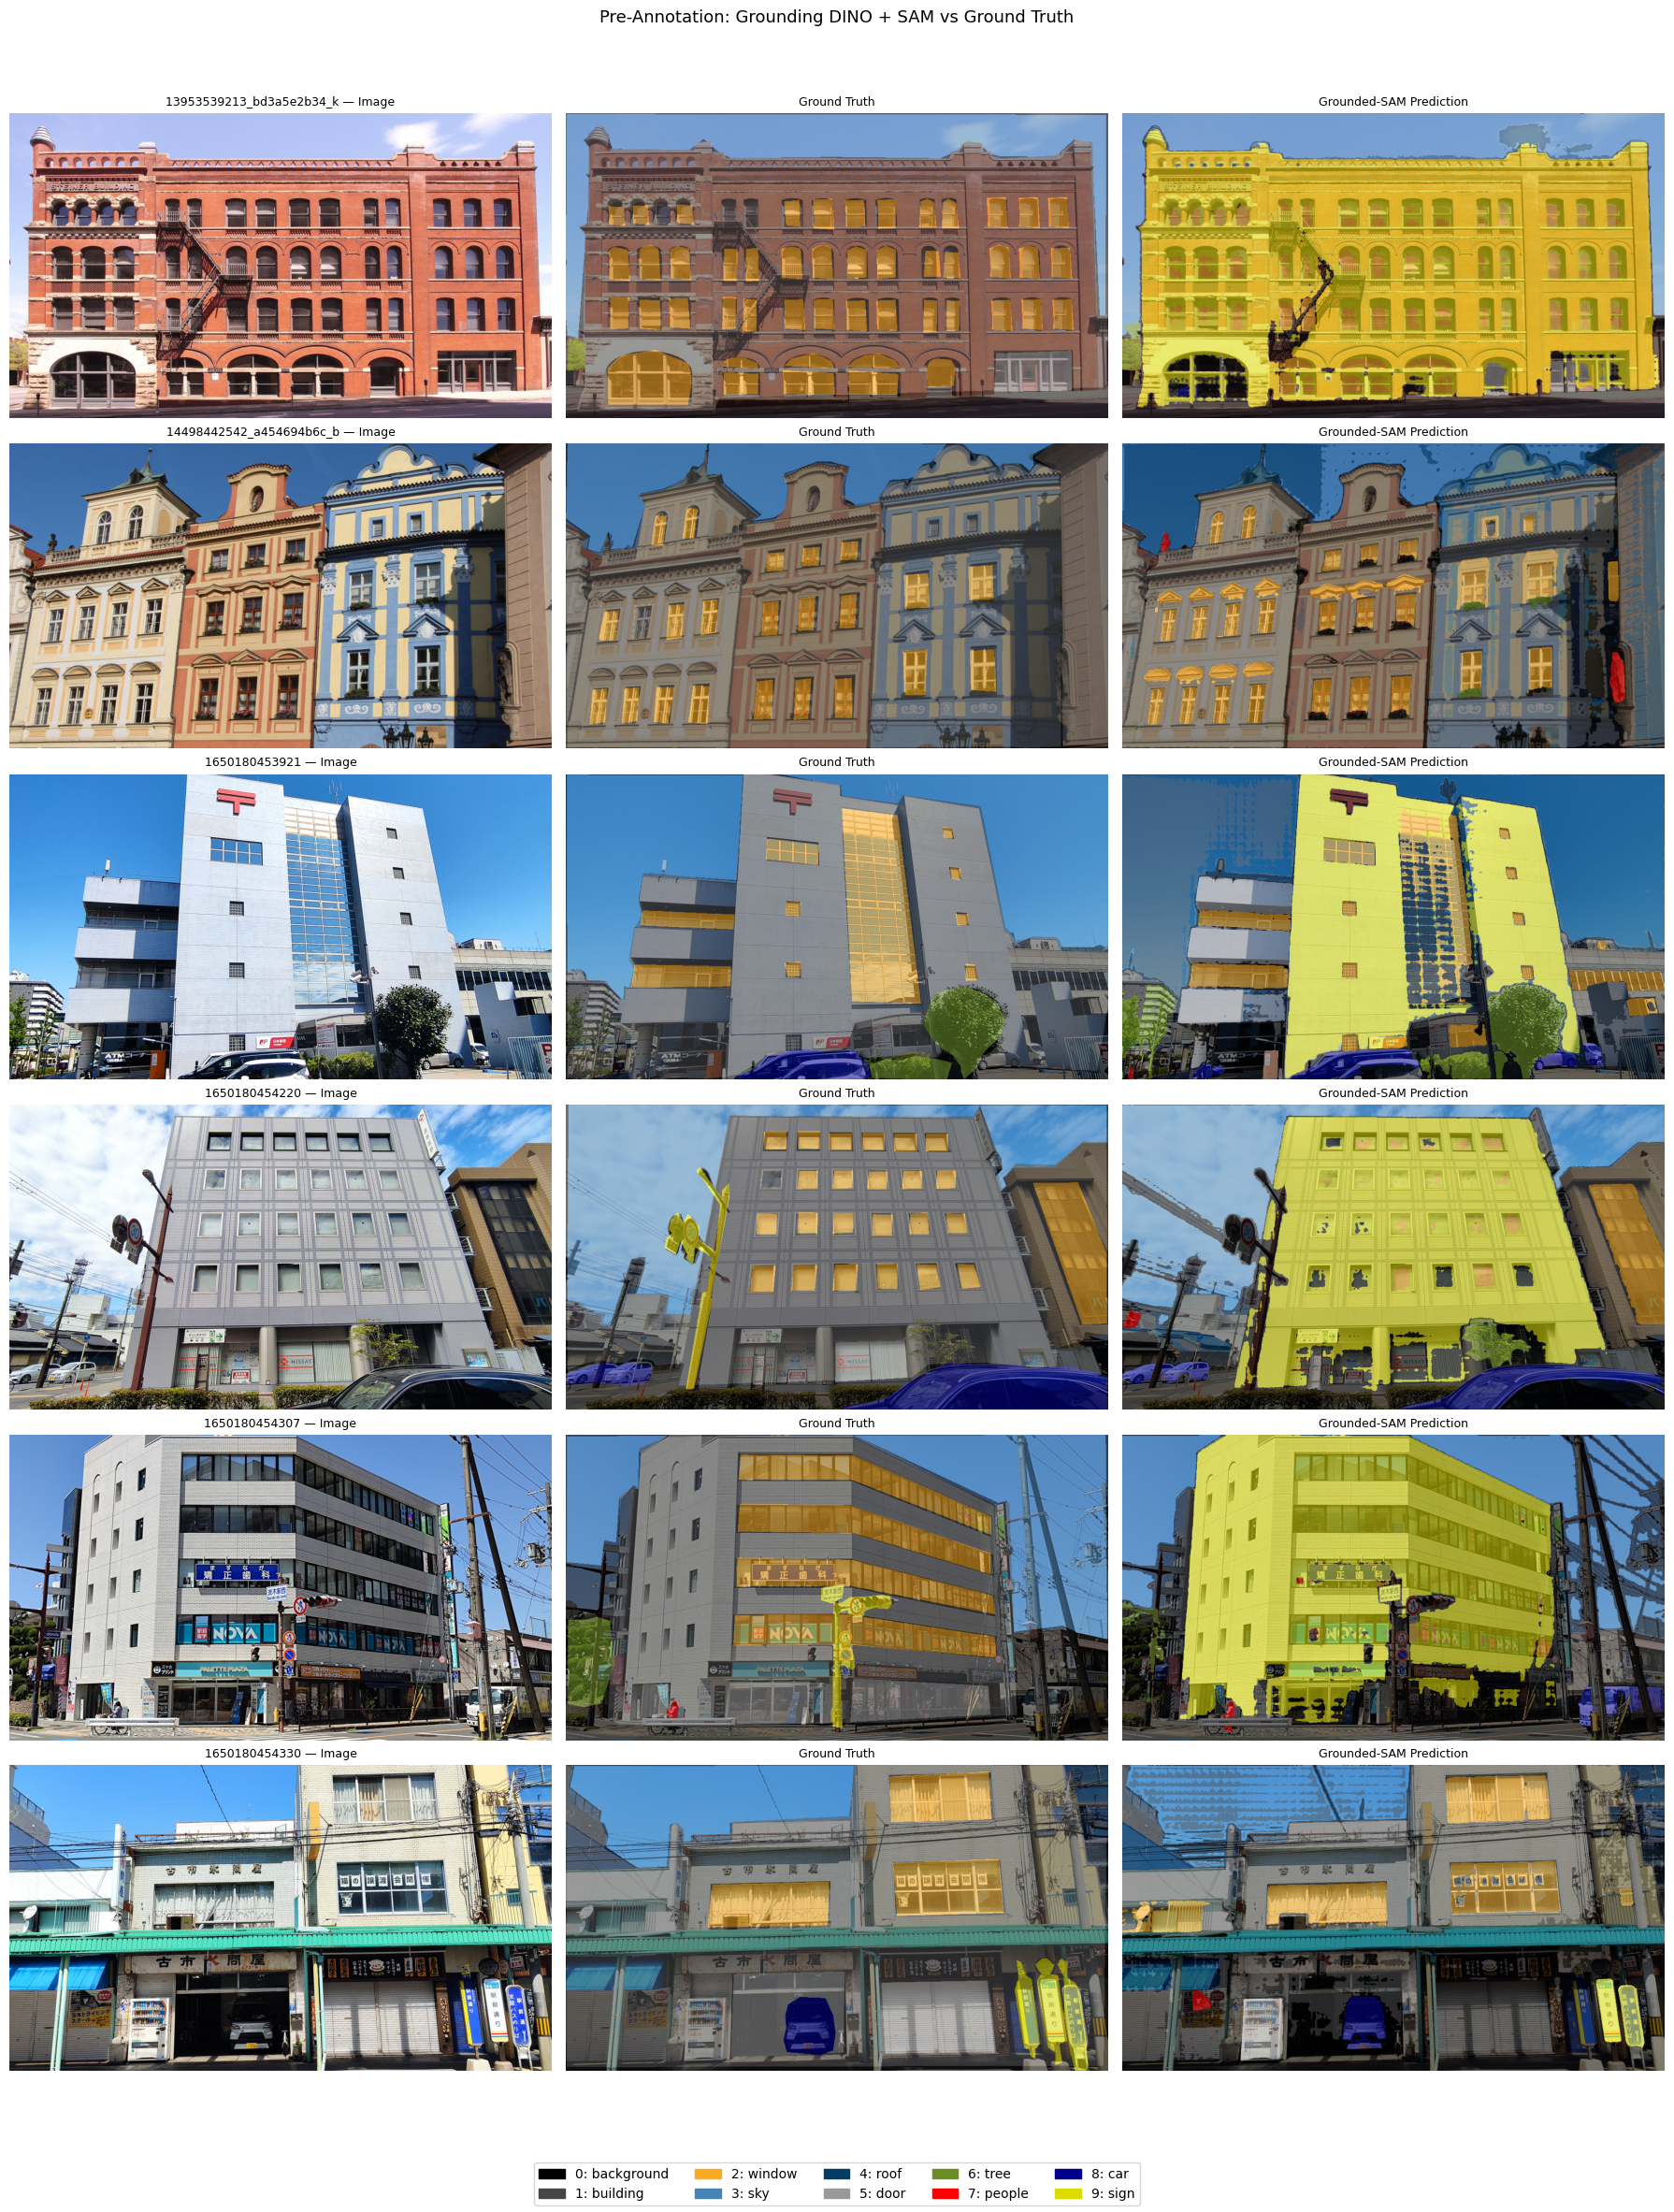

Saved to /kaggle/working/pre_annotation_results/pre_annotation_overlays.png


In [14]:
def mask_to_color(mask):
    h, w = mask.shape
    color = np.zeros((h, w, 3), dtype=np.uint8)
    for cid, rgb in CLASS_COLORS_RGB.items():
        color[mask == cid] = rgb
    return color


samples = test_images[:6]
fig, axes = plt.subplots(len(samples), 3, figsize=(18, 4 * len(samples)))
for i, img_path in enumerate(samples):
    stem = img_path.stem
    img = np.array(Image.open(img_path))
    gt = np.array(Image.open(test_masks[i]))
    pred = pred_masks_all[stem]

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"{stem} — Image", fontsize=9)
    axes[i, 1].imshow(img); axes[i, 1].imshow(mask_to_color(gt), alpha=0.55)
    axes[i, 1].set_title("Ground Truth", fontsize=9)
    axes[i, 2].imshow(img); axes[i, 2].imshow(mask_to_color(pred), alpha=0.55)
    axes[i, 2].set_title("Grounded-SAM Prediction", fontsize=9)
    for a in axes[i]:
        a.axis("off")

patches = [mpatches.Patch(color=np.array(CLASS_COLORS_RGB[c])/255, label=f"{c}: {CLASS_NAMES[c]}")
           for c in range(NUM_CLASSES)]
fig.legend(handles=patches, loc="lower center", ncol=5, fontsize=10)
plt.suptitle("Pre-Annotation: Grounding DINO + SAM vs Ground Truth", fontsize=13)
plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.savefig(OUTPUT_DIR / "pre_annotation_overlays.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Saved to {OUTPUT_DIR / 'pre_annotation_overlays.png'}")

## Save All Results

In [15]:
# Save metrics
metrics = {
    "per_class_iou": {CLASS_NAMES[c]: round(float(mean_iou_per_class[c]) * 100, 1)
                      if not np.isnan(mean_iou_per_class[c]) else None
                      for c in range(NUM_CLASSES)},
    "miou_10_classes": round(float(miou_all) * 100, 1),
    "miou_9_classes_no_bg": round(float(miou_no_bg) * 100, 1),
    "count_analysis": count_analysis,
    "per_image_results": results,
}

with open(OUTPUT_DIR / "pre_annotation_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=str)

print(f"All results saved to {OUTPUT_DIR}")
print("\nFiles to download:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {p.name} ({p.stat().st_size // 1024} KB)")

All results saved to /kaggle/working/pre_annotation_results

Files to download:
  13953539213_bd3a5e2b34_k_pred.png (16 KB)
  14498442542_a454694b6c_b_pred.png (21 KB)
  1650180453921_pred.png (23 KB)
  1650180454220_pred.png (15 KB)
  1650180454307_pred.png (14 KB)
  1650180454330_pred.png (20 KB)
  1650180454510_pred.png (15 KB)
  1650180454547_pred.png (15 KB)
  1650180454576_pred.png (17 KB)
  1650180454764_pred.png (19 KB)
  1650180454796_pred.png (17 KB)
  1650180454855_pred.png (16 KB)
  19416452205_761f434dde_k_pred.png (7 KB)
  2330123762_4a925640cc_k_pred.png (16 KB)
  2957835532_d675b1634e_k_pred.png (13 KB)
  29755814632_1a097f9f59_h_pred.png (14 KB)
  5627932521_cb9b5e24b2_o_pred.png (14 KB)
  8ad30d1b95cd92a86a727c6a9fd910d_pred.png (10 KB)
  IMG_1291_pred.png (17 KB)
  IMG_1294_pred.png (29 KB)
  IMG_1297_pred.png (15 KB)
  IMG_1303_pred.png (29 KB)
  IMG_1304_pred.png (23 KB)
  IMG_1311_pred.png (17 KB)
  IMG_1322_pred.png (21 KB)
  IMG_20220313_112024_pred.png (20 KB)


In [16]:
inter = np.zeros(NUM_CLASSES); union = np.zeros(NUM_CLASSES)
for img_path, gt_path in zip(test_images, test_masks):
    pred = pred_masks_all[img_path.stem]
    gt = np.array(Image.open(gt_path))
    for c in range(NUM_CLASSES):
        inter[c] += ((pred == c) & (gt == c)).sum()
        union[c] += ((pred == c) | (gt == c)).sum()
iou = inter / np.maximum(union, 1)
for c in range(NUM_CLASSES):
    print(f"{CLASS_NAMES[c]:<12s} {iou[c]*100:5.1f}%")
print(f"mIoU (10 classes): {iou.mean()*100:.1f}%")
print(f"mIoU (9 classes, no bg): {iou[1:].mean()*100:.1f}%")
json.dump({"iou_per_class": {CLASS_NAMES[c]: float(iou[c]) for c in range(NUM_CLASSES)},
           "miou_10": float(iou.mean()), "miou_9_no_bg": float(iou[1:].mean())},
          open(OUTPUT_DIR / "pre_annotation_metrics_dataset_level.json", "w"), indent=2)

background    37.9%
building      30.5%
window        41.8%
sky           58.5%
roof           2.0%
door          21.7%
tree          47.2%
people        32.4%
car           58.4%
sign           2.2%
mIoU (10 classes): 33.3%
mIoU (9 classes, no bg): 32.8%
